## Examen Práctico

Daniela Velderrain Lamas

A00227755

## Parte 1

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from scipy import stats
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence

In [3]:
np.random.seed(42)
n = 10

X = np.arange(1, n + 1)                
epsilon = np.random.randn(n) * 0.5     
y = 3 + 0.8 * X + epsilon

df = pd.DataFrame({'X': X, 'y': y})

print(f"Forma del dataset: {df.shape}")
print("\nDatos generados:")
df.round(4)

Forma del dataset: (10, 2)

Datos generados:


,X,y
0,1,4.0484
1,2,4.5309
2,3,5.7238
3,4,6.9615
4,5,6.8829
5,6,7.6829
6,7,9.3896
7,8,9.7837
8,9,9.9653
9,10,11.2713


In [6]:
#Estimación por fórmulas MCO
x_bar = X.mean()
y_bar = y.mean()

Sxx = np.sum((X - x_bar) ** 2)
Sxy = np.sum((X - x_bar) * (y - y_bar))

beta1 = Sxy / Sxx
beta0 = y_bar - beta1 * x_bar

print("=== ESTIMACIÓN POR FÓRMULAS MCO ===\n")
print(f"Sxx = {Sxx:.4f}")
print(f"Sxy = {Sxy:.4f}")
print(f"B0 (intercepto) = {beta0:.4f}")
print(f"B1 (pendiente)  = {beta1:.4f}")
print(f"\nModelo estimado: ŷ = {beta0:.4f} + {beta1:.4f}·X")

=== ESTIMACIÓN POR FÓRMULAS MCO ===

Sxx = 82.5000
Sxy = 65.7154
B0 (intercepto) = 3.2430
B1 (pendiente)  = 0.7965

Modelo estimado: ŷ = 3.2430 + 0.7965·X


In [8]:
#Solución matricial
X_design = np.column_stack([np.ones(n), X])

XtX = X_design.T @ X_design
XtX_inv = np.linalg.inv(XtX)
beta_mat = XtX_inv @ X_design.T @ y

print("=== SOLUCIÓN MATRICIAL ===\n")
print("XᵀX =\n", XtX)
print("\n(XᵀX)⁻¹ =\n", XtX_inv.round(4))
print(f"\nMatricial = {beta_mat.round(4)}")
print(f"Fórmulas  = {np.array([beta0, beta1]).round(4)}")

=== SOLUCIÓN MATRICIAL ===

XᵀX =
 [[ 10.  55.]
 [ 55. 385.]]

(XᵀX)⁻¹ =
 [[ 0.4667 -0.0667]
 [-0.0667  0.0121]]

Matricial = [3.243  0.7965]
Fórmulas  = [3.243  0.7965]


In [ ]:
#Suma de cuadrados
y_hat = beta0 + beta1 * X
e = y - y_hat

SST = np.sum((y - y_bar) ** 2)
SSR = np.sum((y_hat - y_bar) ** 2)
SSE = np.sum(e ** 2)

print("=== SUMAS DE CUADRADOS ===\n")
print(f"SST = {SST:.4f}")
print(f"SSR = {SSR:.4f}")
print(f"SSE = {SSE:.4f}")
print(f"\nSSR + SSE = {SSR + SSE:.4f}")

=== SUMAS DE CUADRADOS ===

SST = 53.5207
SSR = 52.3456
SSE = 1.1752

SSR + SSE = 53.5207


In [13]:
#ANOVA
df_reg = 1
df_err = n - 2
df_tot = n - 1

MSR = SSR / df_reg
MSE = SSE / df_err
F = MSR / MSE
R2 = SSR / SST
p_F = stats.f.sf(F, df_reg, df_err)

anova = pd.DataFrame({
    'Fuente': ['Regresión', 'Error', 'Total'],
    'SC': [SSR, SSE, SST],
    'gl': [df_reg, df_err, df_tot],
    'CM': [MSR, MSE, np.nan],
    'F': [F, np.nan, np.nan],
    'p-valor': [p_F, np.nan, np.nan]
})

print("=== TABLA ANOVA ===\n")
anova_print = anova.round(4).astype(object)
anova_print['p-valor'] = anova['p-valor'].map(lambda v: '' if pd.isna(v) else f'{v:.2e}')
print(anova_print.fillna('').to_string(index=False))
print(f"\nMSR = {MSR:.4f}   MSE = {MSE:.4f}   F = {F:.4f}   R² = {R2:.4f}")

=== TABLA ANOVA ===

   Fuente       SC gl       CM         F  p-valor
Regresión  52.3456  1  52.3456  356.3391 6.41e-08
    Error   1.1752  8   0.1469                   
    Total  53.5207  9                            

MSR = 52.3456   MSE = 0.1469   F = 356.3391   R² = 0.9780


In [ ]:
#Errores estándar e IC explícitos, con las pruebas t individuales
se_b1 = np.sqrt(MSE / Sxx)
se_b0 = np.sqrt(MSE * (1 / n + x_bar ** 2 / Sxx))

t_crit = stats.t.ppf(0.975, df_err)

resultados = []
for nombre, b, se in [('B0 (intercepto)', beta0, se_b0), ('B1 (pendiente)', beta1, se_b1)]:
    t_val = b / se
    p_val = 2 * stats.t.sf(abs(t_val), df_err)
    resultados.append({
        'Parámetro': nombre, 'Estimación': b, 'SE': se, 't': t_val, 'p-valor': p_val,
        'IC 95% inf': b - t_crit * se, 'IC 95% sup': b + t_crit * se
    })

tabla_coef = pd.DataFrame(resultados)

print("=== ERRORES ESTÁNDAR E IC AL 95% ===\n")
print(f"t crítico (gl = {df_err}, 95%) = {t_crit:.4f}\n")
tabla_print = tabla_coef.round(4).astype(object)
tabla_print['p-valor'] = tabla_coef['p-valor'].map(lambda v: f'{v:.2e}')
print(tabla_print.to_string(index=False))

=== ERRORES ESTÁNDAR E IC AL 95% ===

t crítico (gl = 8, 95%) = 2.3060

      Parámetro Estimación      SE        t  p-valor IC 95% inf IC 95% sup
B0 (intercepto)      3.243  0.2618  12.3861 1.68e-06     2.6392     3.8468
 B1 (pendiente)     0.7965  0.0422  18.8769 6.41e-08     0.6992     0.8939


In [17]:
#Verificación
t_b1 = beta1 / se_b1

print("=== VERIFICACIÓN F = t² ===\n")
print(f"t de B1 = {t_b1:.4f}")
print(f"t² = {t_b1 ** 2:.4f}")
print(f"F  = {F:.4f}")

modelo_sm = sm.OLS(y, sm.add_constant(X)).fit()
print(modelo_sm.summary())

modelo_sk = LinearRegression().fit(X.reshape(-1, 1), y)
print(f"\nsklearn: intercepto = {modelo_sk.intercept_:.4f}, pendiente = {modelo_sk.coef_[0]:.4f}")

=== VERIFICACIÓN F = t² ===

t de B1 = 18.8769
t² = 356.3391
F  = 356.3391
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.978
Model:                            OLS   Adj. R-squared:                  0.975
Method:                 Least Squares   F-statistic:                     356.3
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           6.41e-08
Time:                        23:05:27   Log-Likelihood:                -3.4836
No. Observations:                  10   AIC:                             10.97
Df Residuals:                       8   BIC:                             11.57
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------

Text(0, 0.5, 'Residuo')

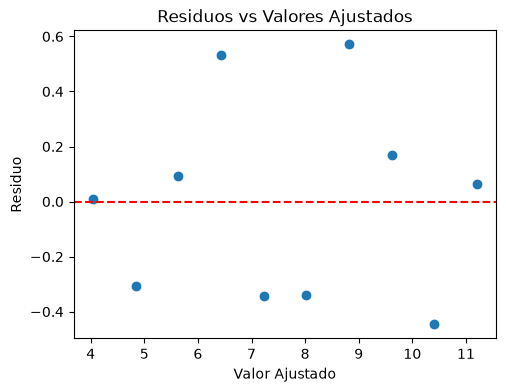

In [18]:
#gráfica
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.scatterplot(x=y_hat, y=e, s=60)
plt.axhline(y=0, color='r', linestyle='--')
plt.title('Residuos vs Valores Ajustados')
plt.xlabel('Valor Ajustado')
plt.ylabel('Residuo')

In [21]:
#distancia de hook
p = 2
D = (e ** 2 / (p * MSE)) * (h / (1 - h) ** 2)

print(f"\nUmbral de leverage 2p/n = {2 * p / n:.2f}")
print(f"Distancia de Cook máxima = {D.max():.4f} (obs. con X = {X[D.argmax()]})")
print(f"Observaciones con D > 1: {int((D > 1).sum())}")


Umbral de leverage 2p/n = 0.40
Distancia de Cook máxima = 0.2988 (obs. con X = 9)
Observaciones con D > 1: 0


## Parte 2

In [22]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from scipy import stats



In [23]:
#exploración
data = load_wine()
X_all = pd.DataFrame(data.data, columns=data.feature_names)

predictores = ['total_phenols', 'od280/od315_of_diluted_wines', 'proline']
respuesta = 'flavanoids'

df = X_all[predictores + [respuesta]].copy()
X = df[predictores]
y = df[respuesta]

print(f"Forma del dataset: {df.shape}")
df.head()

Forma del dataset: (178, 4)


,total_phenols,od280/od315_of_diluted_wines,proline,flavanoids
0,2.80,3.92,1065.0,3.06
1,2.65,3.40,1050.0,2.76
2,2.80,3.17,1185.0,3.24
3,3.85,3.45,1480.0,3.49
4,2.80,2.93,735.0,2.69


MATRIZ DE CORRELACIÓN ENTRE PREDICTORES

                              total_phenols  od280/od315_of_diluted_wines  \
total_phenols                        1.0000                        0.6999   
od280/od315_of_diluted_wines         0.6999                        1.0000   
proline                              0.4981                        0.3128   

                              proline  
total_phenols                  0.4981  
od280/od315_of_diluted_wines   0.3128  
proline                        1.0000  

CORRELACIÓN DE CADA PREDICTOR CON LA RESPUESTA (flavanoids)

total_phenols                   0.8646
od280/od315_of_diluted_wines    0.7872
proline                         0.4942
Name: flavanoids, dtype: float64


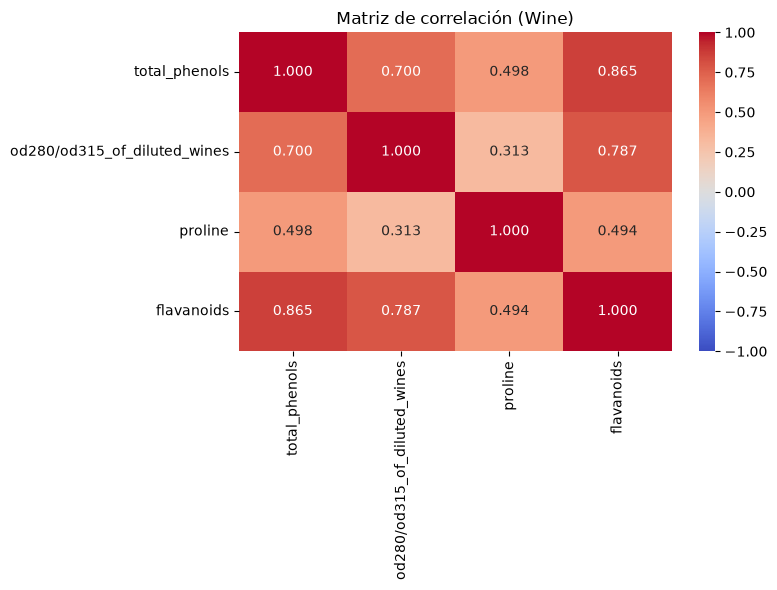

In [25]:
#matriz ce correlación
print("MATRIZ DE CORRELACIÓN ENTRE PREDICTORES\n")
corr_pred = X.corr()
print(corr_pred.round(4))

print("\nCORRELACIÓN DE CADA PREDICTOR CON LA RESPUESTA (flavanoids)\n")
print(df.corr()[respuesta].drop(respuesta).round(4))

pares = corr_pred.where(np.triu(np.ones(corr_pred.shape), k=1).astype(bool)).stack()
par_max = pares.abs().idxmax()

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt='.3f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación (Wine)')
plt.tight_layout()
plt.show()

**¿Qué par de predictores está más correlacionados?**

Los predictores más correlacionados son "total_phenols" y "od280/od315_of_diluted_wines", ya que cuenta con un r = 0.699. 

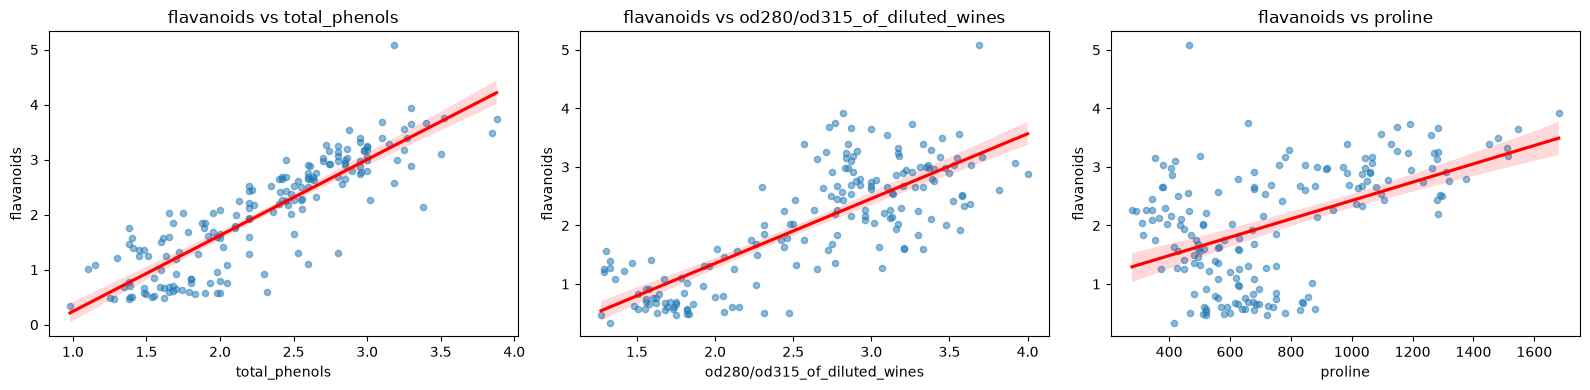

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, var in zip(axes, predictores):
    sns.regplot(x=var, y=respuesta, data=df, ax=ax, scatter_kws={'alpha': 0.5, 's': 20},
                line_kws={'color': 'red'})
    ax.set_title(f'flavanoids vs {var}')

plt.tight_layout()
plt.show()

In [27]:
#solución matricial
n = len(y)
p = len(predictores)          
k = p + 1                    

X_design = np.column_stack([np.ones(n), X.values])
y_vec = y.values

XtX = X_design.T @ X_design
XtX_inv = np.linalg.inv(XtX)
beta = XtX_inv @ X_design.T @ y_vec

y_hat = X_design @ beta
e = y_vec - y_hat

SSE = np.sum(e ** 2)
df_err = n - k
MSE = SSE / df_err

se = np.sqrt(MSE * np.diag(XtX_inv))
t_vals = beta / se
p_vals = 2 * stats.t.sf(np.abs(t_vals), df_err)

nombres = ['const'] + predictores
tabla_coef = pd.DataFrame({'Coeficiente': beta, 'SE': se, 't': t_vals, 'p-valor': p_vals}, index=nombres)

print("=== COEFICIENTES (SOLUCIÓN MATRICIAL) ===\n")
print(f"n = {n},  parámetros k = {k},  gl del error = {df_err},  MSE = {MSE:.4f}\n")
tabla_print = tabla_coef.copy().astype(object)
tabla_print['Coeficiente'] = tabla_coef['Coeficiente'].map(lambda v: f'{v:.5f}')
tabla_print['SE'] = tabla_coef['SE'].map(lambda v: f'{v:.5f}')
tabla_print['t'] = tabla_coef['t'].map(lambda v: f'{v:.3f}')
tabla_print['p-valor'] = tabla_coef['p-valor'].map(lambda v: f'{v:.2e}')
print(tabla_print)

=== COEFICIENTES (SOLUCIÓN MATRICIAL) ===

n = 178,  parámetros k = 4,  gl del error = 174,  MSE = 0.1825

                             Coeficiente       SE        t   p-valor
const                           -1.59735  0.13387  -11.932  2.29e-24
total_phenols                    0.89213  0.07882   11.319  1.31e-22
od280/od315_of_diluted_wines     0.51219  0.06343    8.076  1.07e-13
proline                          0.00032  0.00012    2.744  6.71e-03


In [29]:
#ANOVA múltiple
y_bar = y_vec.mean()

SST = np.sum((y_vec - y_bar) ** 2)
SSR = np.sum((y_hat - y_bar) ** 2)

df_reg = p
df_tot = n - 1

MSR = SSR / df_reg
F = MSR / MSE
p_F = stats.f.sf(F, df_reg, df_err)

R2 = SSR / SST
R2_adj = 1 - (1 - R2) * (n - 1) / (n - p - 1)

anova = pd.DataFrame({
    'Fuente': ['Regresión', 'Error', 'Total'],
    'SC': [SSR, SSE, SST],
    'gl': [df_reg, df_err, df_tot],
    'CM': [MSR, MSE, np.nan],
    'F': [F, np.nan, np.nan],
    'p-valor': [f'{p_F:.2e}', '', '']
})

print("=== TABLA ANOVA ===\n")
print(anova.round(4).fillna('').to_string(index=False))
print(f"\nF global = {F:.3f}  (gl = {df_reg}, {df_err}),  p-valor = {p_F:.2e}")
print(f"R²          = {R2:.4f}")
print(f"R² ajustado = {R2_adj:.4f}")

=== TABLA ANOVA ===

   Fuente       SC  gl       CM         F  p-valor
Regresión 144.8478   3  48.2826  264.6172 1.39e-64
    Error  31.7484 174   0.1825                   
    Total 176.5962 177                            

F global = 264.617  (gl = 3, 174),  p-valor = 1.39e-64
R²          = 0.8202
R² ajustado = 0.8171


In [32]:
#multicolinealidad (VIF)
vif_manual = {}
for var in predictores:
    otros = [v for v in predictores if v != var]
    aux = sm.OLS(X[var], sm.add_constant(X[otros])).fit()
    vif_manual[var] = {'R² auxiliar': aux.rsquared, 'VIF': 1 / (1 - aux.rsquared)}

vif_tabla = pd.DataFrame(vif_manual).T

print("=== FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ===\n")
print(vif_tabla.round(4))
print(f"Variable con mayor VIF: {vif_tabla['VIF'].idxmax()} ({vif_tabla['VIF'].max():.3f})")

=== FACTOR DE INFLACIÓN DE LA VARIANZA (VIF) ===

                              R² auxiliar     VIF
total_phenols                      0.5763  2.3603
od280/od315_of_diluted_wines       0.4916  1.9671
proline                            0.2506  1.3345
Variable con mayor VIF: total_phenols (2.360)


**¿Que problema presenta problema grave (VIF = 10)? ¿Por qué?**

Ni una variable llega a presentar algún problema, todas están debajo del rango de 10. La correlación entre predictores esta moderada, sin multicolinealidad.

In [37]:
#leverage y cook
H = X_design @ XtX_inv @ X_design.T
h = np.diag(H)

D = (e ** 2 / (k * MSE)) * (h / (1 - h) ** 2)

umbral_h = 2 * k / n
alto_lev = np.where(h > umbral_h)[0]

print("=== LEVERAGE ===\n")
print(f"Suma de h_ii = {h.sum():.4f}")
print(f"Umbral 2k/n = {umbral_h:.4f}   (con 2p/n y p = 3 sería {2 * p / n:.4f})")
print(f"Observaciones con h_ii= 2k/n: {len(alto_lev)} ,  índices: {alto_lev.tolist()}")
print(f"h_ii máximo = {h.max():.4f} (obs. {h.argmax()})")

print("\n=== DISTANCIA DE COOK ===\n")
print(f"D máxima = {D.max():.4f} (obs. {D.argmax()})")
print(f"Observaciones con D > 1: {int((D > 1).sum())}")

top5 = pd.DataFrame({'obs': np.argsort(-D)[:5], 'Cook_D': np.sort(D)[::-1][:5],
                     'h_ii': h[np.argsort(-D)[:5]], 'residuo': e[np.argsort(-D)[:5]]})
print("\nLas 5 observaciones con mayor distancia de Cook:")
print(top5.round(4).to_string(index=False))

=== LEVERAGE ===

Suma de h_ii = 4.0000
Umbral 2k/n = 0.0449   (con 2p/n y p = 3 sería 0.0337)
Observaciones con h_ii= 2k/n: 8 ,  índices: [3, 14, 18, 52, 63, 98, 105, 152]
h_ii máximo = 0.0695 (obs. 63)

=== DISTANCIA DE COOK ===

D máxima = 0.1844 (obs. 121)
Observaciones con D > 1: 0

Las 5 observaciones con mayor distancia de Cook:
 obs  Cook_D   h_ii  residuo
 121  0.1844 0.0384   1.8001
  74  0.0527 0.0267  -1.1676
 150  0.0433 0.0252   1.0909
 158  0.0370 0.0383  -0.8078
  18  0.0338 0.0612   0.5960


In [40]:
#comparación de modelos
def evaluar_modelo(vars_list):
    Xm = sm.add_constant(X[vars_list])
    mod = sm.OLS(y, Xm).fit()

    k_m = len(vars_list) + 1
    sse_m = np.sum(mod.resid ** 2)
    logL = -n / 2 * (np.log(2 * np.pi) + np.log(sse_m / n) + 1)
    aic = -2 * logL + 2 * k_m
    bic = -2 * logL + k_m * np.log(n)

    assert np.isclose(aic, mod.aic) and np.isclose(bic, mod.bic)   # coincide con statsmodels
    return {'k': k_m, 'R²': mod.rsquared, 'R² ajustado': mod.rsquared_adj,
            'logL': logL, 'AIC': aic, 'BIC': bic}

var_mayor_vif = vif_tabla['VIF'].idxmax()
vars_reducido = [v for v in predictores if v != var_mayor_vif]

print("=== COMPARACIÓN DE MODELOS ===\n")
print(f"Variable con mayor VIF: {var_mayor_vif}\n")

modelos = {
    'Completo': predictores,
    f'Reducido (sin {var_mayor_vif})': vars_reducido,
}
for v in predictores:
    if v != var_mayor_vif:
        modelos[f'sin {v}'] = [q for q in predictores if q != v]

comp = pd.DataFrame({nombre: evaluar_modelo(vs) for nombre, vs in modelos.items()}).T
print(comp.round(4))

=== COMPARACIÓN DE MODELOS ===

Variable con mayor VIF: total_phenols

                                    k      R²  R² ajustado      logL  \
Completo                          4.0  0.8202       0.8171  -99.1403   
Reducido (sin total_phenols)      3.0  0.6878       0.6843 -148.2488   
sin od280/od315_of_diluted_wines  3.0  0.7528       0.7500 -127.4694   
sin proline                       3.0  0.8124       0.8103 -102.9105   

                                       AIC       BIC  
Completo                          206.2806  219.0077  
Reducido (sin total_phenols)      302.4975  312.0429  
sin od280/od315_of_diluted_wines  260.9388  270.4841  
sin proline                       211.8211  221.3664  


**¿Qué información aporta el VIF que el R² no captura? ¿Qué implica que un coeficiente cambie de signo al eliminar otra variable?**

El R² dice qué tan bien el modelo explica la respuesta, pero no dice nada sobre la relación entre los predictores. El VIF mide qué tan redundante es cada predictor respecto a los demás.

Si un coeficiente cambia de signo al quitar otra variable, es señal de que ambas comparten información. Pero, con estos datos no ocurre estp, ya que al quitar "total_phenols" los signos se mantienen, pero los coeficientes sí cambian de tamaño. Entonces, confirma que tienen información similar.